# Behavioural analysis 002

## Imports

In [2]:
%load_ext autoreload
%autoreload 2
import sys

sys.path.append('../../')

In [3]:
from pathlib import Path
from joblib import dump, load

import numpy as np
import matplotlib.pyplot as plt

import pyaldata as pyal
import tools.dsp as dsp
from tools.params import Params
import tools.dataTools as dt
import tools.kinematics as kin
import tools.viz.utilityTools as vizutils
import tools.dimensionality as dim
import pandas as pd
from scipy import stats
from scipy.stats import gaussian_kde
from matplotlib.lines import Line2D

import bhv
from bhv import ACCENT, ANGLE_COLOR, DIM_COLOR, EXAMPLE, GROUP_COLOR, LEVEL_STYLE, MARG_NAME, NEUTRAL, REGIONS, DIMS, animal_means, bar_style

## Generate dpca cache

### Load bhv

In [4]:
CACHE = Path("/mnt/mouse-data-london/proc") / "cache" / "bhv"
CACHE.mkdir(parents=True, exist_ok=True)

SESSIONS_DPCA = [
    "M061_2025_03_04_10_00",
    "M061_2025_03_05_14_00",
    "M061_2025_03_06_14_00",
    "M062_2025_03_20_14_00",
    "M062_2025_03_21_14_00",
    "M078_2025_08_06_15_00",
    "M086_2025_12_10_15_00",
    "M103_2026_02_18_15_30",
    "M106_2026_02_25_15_00",
]

In [5]:
s = bhv.load_bhv_cache(SESSIONS_DPCA, CACHE)

### Run dpca

In [ ]:
import os

os.environ.setdefault("NUMEXPR_MAX_THREADS", "1")

FACTORS, LABELS, K, N_SHUFFLES, SEED = ["level", "angle"], "lpt", 10, 1000, 0
FS, BASE, RESPONSE = 100, (-1.6, -0.1), (-0.5, 1.5)

DPCA_CACHE = CACHE / "dpca" / f"{LABELS}_rauto_k{K}"
DPCA_CACHE.mkdir(parents=True, exist_ok=True)


def dpca_session(sess):
    """Run ``dim.noise_floor`` on one session's baseline-z-scored response window and cache it in ``DPCA_CACHE``.

    Parameters
    ----------
    sess : str
        Session name, a key of ``s``.

    Returns
    -------
    dict
        The stats saved in ``<sess>.npz``.
    """
    f = DPCA_CACHE / f"{sess}.npz"
    if f.exists():
        return dict(np.load(f))
    d = s[sess]
    win = lambda w: slice(200 + int(w[0] * FS), 200 + int(w[1] * FS))
    X = d["bhv_rot"]
    assert np.isfinite(X).all(), f"{sess}: non-finite values in bhv_rot"
    X = (X / X[:, win(BASE)].std(axis=1, keepdims=True))[:, win(RESPONSE)].transpose(0, 2, 1)
    stats, fit = dim.noise_floor(
        X, d["codes"], FACTORS, LABELS, regularizer="auto", n_components=K, n_shuffles=N_SHUFFLES, seed=SEED
    )
    np.savez(f, session=sess, **stats)
    dump(fit, DPCA_CACHE / f"{sess}_fit.joblib", compress=3)
    return stats

In [ ]:
dpca = {sess: dpca_session(sess) for sess in SESSIONS_DPCA}

## Load dpca cache

In [8]:
def load_fit(sess):
    """Load the fitted dPCA model and tensors saved for one session.

    Parameters
    ----------
    sess : str
        Session name, one of ``SESSIONS_DPCA``.

    Returns
    -------
    dict
        dpca, X_psth, trialX, codes, cond_values and config.
    """
    return load(DPCA_CACHE / f"{sess}_fit.joblib")


missing = [k for k in SESSIONS_DPCA if not (DPCA_CACHE / f"{k}.npz").exists()]
assert not missing, f"no dPCA results for {missing} in {DPCA_CACHE} -- run the dPCA cell first"
dpca_res = {k: {**np.load(DPCA_CACHE / f"{k}.npz"), **load_fit(k)} for k in SESSIONS_DPCA}

## Cumulative explained variance and the signal ceiling

In [9]:
N_SHOW = 20  # components plotted; the summary below uses all of them
STYLE = dict(pca=dict(color=NEUTRAL, label="PCA"), dpca=dict(color=ACCENT, label="dPCA"))

cum = {}
for sess, r in dpca_res.items():
    dpca_cum, pca_cum = dim.cumulative_explained_variance(r["dpca"], r["X_psth"])
    signal = 100 * dim.signal_variance_fraction(r["X_psth"], r["trialX"])
    cum[sess] = dict(dpca=dpca_cum, pca=pca_cum, signal=signal)

q = np.arange(1, N_SHOW + 1)

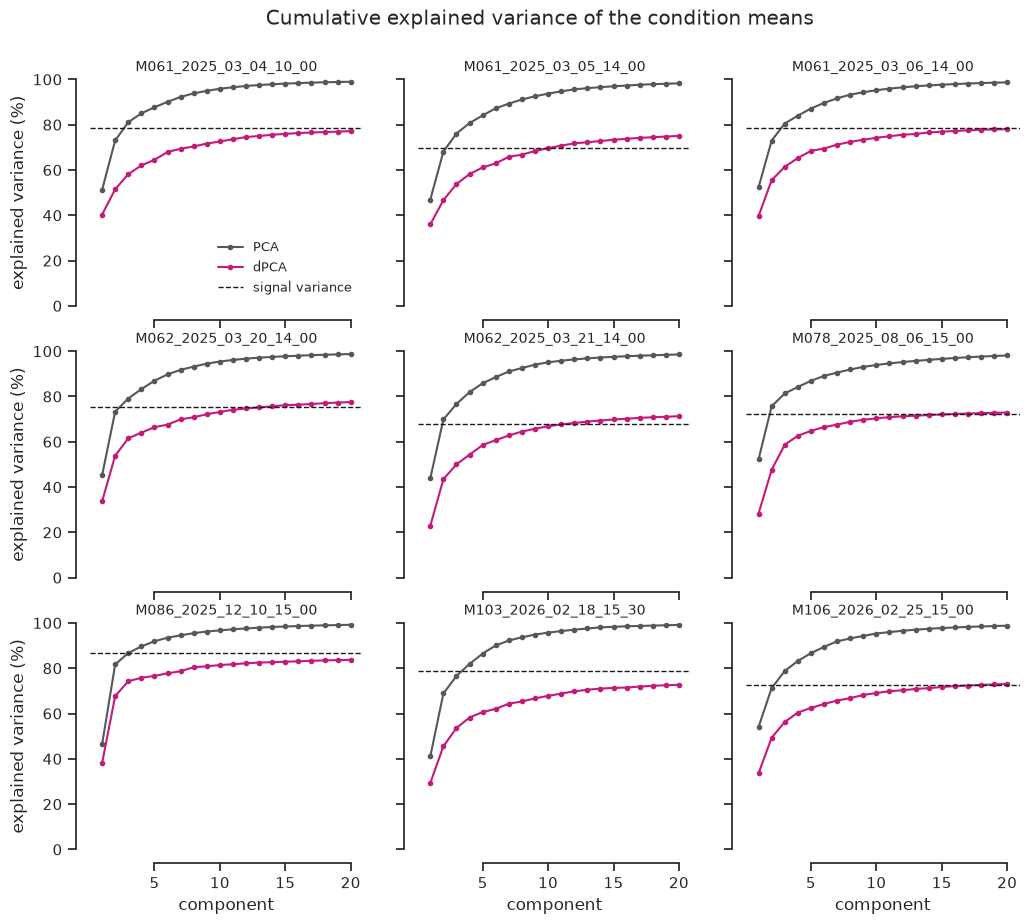

signal variance       75.5% [67.9, 86.6]
dPCA, 10 components   70.3% [66.9, 81.4]   PCA, 10 components  95.3% [93.7, 96.7]
dPCA, all components  76.8% [72.4, 84.5]   ends below signal line in 3/9 sessions


In [10]:
with vizutils.apply_plot_style("notebook"):
    fig, axs = plt.subplots(3, 3, figsize=(12, 10), sharex=True, sharey=True)
    for ax, (sess, c) in zip(axs.flat, cum.items()):
        for key, style in STYLE.items():
            ax.plot(q, c[key][:N_SHOW], "-o", ms=3, **style)
        ax.axhline(c["signal"], color="k", ls="--", lw=1, label="signal variance")
        ax.set_title(sess, fontsize=10)
        ax.set_ylim(0, 100)
    axs[0, 0].legend(frameon=False, fontsize=9, loc="lower right")
    for ax in axs[:, 0]:
        ax.set_ylabel("explained variance (%)")
    for ax in axs[-1]:
        ax.set_xlabel("component")
    fig.suptitle("Cumulative explained variance of the condition means", y=0.95)
plt.show()

# across sessions: median [range], and how often dPCA (all components) ends below the signal line
sig = np.array([c["signal"] for c in cum.values()])
d10, p10, dall = (np.array([c[k][i] for c in cum.values()]) for k, i in (("dpca", 9), ("pca", 9), ("dpca", -1)))
fmt = lambda v: f"{np.median(v):5.1f}% [{v.min():.1f}, {v.max():.1f}]"
print(f"signal variance      {fmt(sig)}")
print(f"dPCA, 10 components  {fmt(d10)}   PCA, 10 components {fmt(p10)}")
print(f"dPCA, all components {fmt(dall)}   ends below signal line in {(dall < sig).sum()}/{len(sig)} sessions")

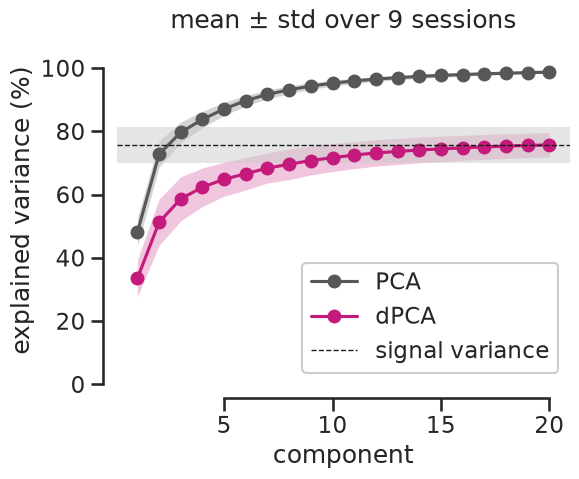

In [11]:
with vizutils.apply_plot_style("talk"):
    fig, ax = plt.subplots(figsize=(6, 5))
    for key, style in STYLE.items():
        acc = np.array([c[key][:N_SHOW] for c in cum.values()])
        m, std = acc.mean(axis=0), acc.std(axis=0, ddof=1)
        ax.fill_between(q, m - std, m + std, color=style["color"], alpha=0.25, lw=0)
        ax.plot(q, m, **style, marker='o')
    sig = np.array([c["signal"] for c in cum.values()])
    ax.axhspan(sig.mean() - sig.std(ddof=1), sig.mean() + sig.std(ddof=1), color="0.8", alpha=0.5, lw=0)
    ax.axhline(sig.mean(), color="k", lw=1, label="signal variance", ls='--')
    ax.set_ylim(0, 110)
    ax.set_xlabel("component")
    ax.set_ylabel("explained variance (%)")
    ax.legend(frameon=True, framealpha=1, facecolor="white", loc="lower right")
    ax.set_title(f"mean ± std over {len(cum)} sessions")
    plt.tight_layout()
plt.show()

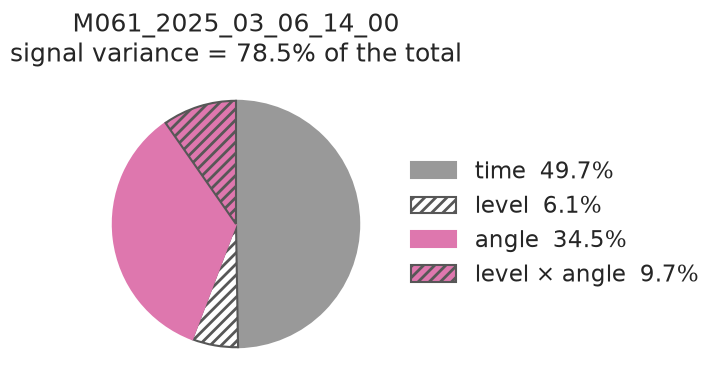

In [12]:
r = dpca_res[EXAMPLE]
ceiling = dim.signal_variance_fraction(r["X_psth"], r["trialX"])
share = 100 * r["signal_frac"]  # noise-corrected: each marginalization's % of the signal variance

with vizutils.apply_plot_style("talk"), plt.rc_context({"hatch.linewidth": 2}):
    fig, ax = plt.subplots(figsize=(5, 4))
    wedges, _ = ax.pie(share, startangle=90, counterclock=False)
    for w, key in zip(wedges, r["keys"]):
        w.set(lw=1.5, **bar_style(key))
    labels = [f"{MARG_NAME[k]}  {v:.1f}%" for k, v in zip(r["keys"], share)]
    ax.legend(wedges, labels, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
    ax.set_title(f"{EXAMPLE}\nsignal variance = {100 * ceiling:.1f}% of the total")
plt.show()

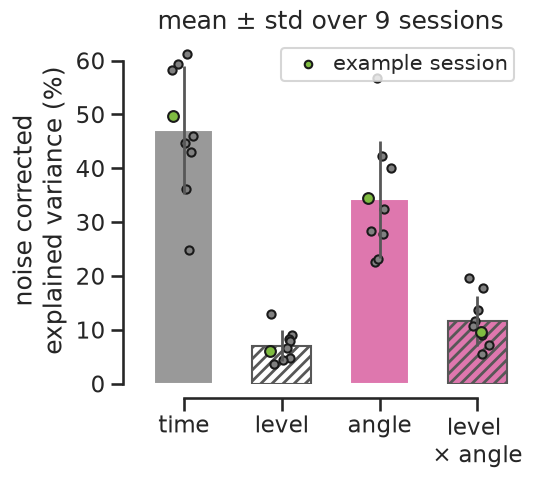

In [13]:
keys = list(dpca_res[SESSIONS_DPCA[0]]["keys"])
share = np.array([100 * r["signal_frac"] for r in dpca_res.values()])  # (sessions, marginalizations), % of signal
rng = np.random.default_rng(0)
ex = list(dpca_res).index(EXAMPLE)

with vizutils.apply_plot_style("talk"), plt.rc_context({"hatch.linewidth": 2}):
    fig, ax = plt.subplots(figsize=(5, 4.5))
    for j, key in enumerate(keys):
        ax.bar(j, share[:, j].mean(), width=0.6, lw=1.5, **bar_style(key))
        ax.errorbar(j, share[:, j].mean(), yerr=share[:, j].std(ddof=1), color=NEUTRAL, lw=2, capsize=0, zorder=4)
        x = j + rng.uniform(-0.12, 0.12, len(share))
        ax.scatter(np.delete(x, ex), np.delete(share[:, j], ex), facecolor="0.5", edgecolor="k", s=35, zorder=3)
        ax.scatter(x[ex], share[ex, j], facecolor=bhv.EXAMPLE_COLOR, edgecolor="k", s=60, zorder=5, label="example session" if j == 0 else None)
    ax.set_xticks(range(len(keys)), [MARG_NAME[k].replace(" × ", " \n× ") for k in keys])
    ax.set_ylabel("noise corrected\nexplained variance (%)")
    ax.set_title(f"mean ± std over {len(share)} sessions")
    ax.legend(fontsize="small", markerscale=0.7, handletextpad=0.2, borderpad=0.3)
plt.show()

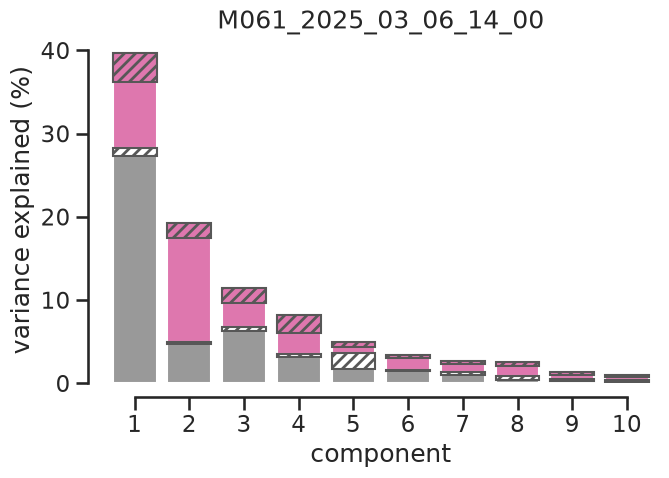

In [14]:
N_COMP = 10

r = dpca_res[EXAMPLE]
component_var, marg_var, which_marg, _ = dim.get_var_split(r["dpca"], r["X_psth"])  # marg_var: (marginalizations, components)
x = np.arange(1, N_COMP + 1)

with vizutils.apply_plot_style("talk"), plt.rc_context({"hatch.linewidth": 2}):
    fig, ax = plt.subplots(figsize=(0.42 * N_COMP + 3, 4.5))
    bottom = np.zeros(N_COMP)
    for j, key in enumerate(r["keys"]):
        hatched = "hatch" in bhv.FACTOR_BAR[bhv.MARG_STYLE[key]]  # drawn on top, so a neighbouring segment cannot cover the outline
        ax.bar(x, marg_var[j, :N_COMP], bottom=bottom, width=0.8, lw=1.5, label=MARG_NAME[key],
               zorder=3 if hatched else 2, **bar_style(key))
        bottom += marg_var[j, :N_COMP]
    ax.set_xticks(x, x)
    ax.set_xlim(0.4, N_COMP + 0.6)
    ax.set_xlabel("component")
    ax.set_ylabel("variance explained (%)")
    ax.set_title(f"{EXAMPLE}")
    # ax.legend(title="marginalization", frameon=False, fontsize="small")
    # plt.tight_layout()
plt.show()

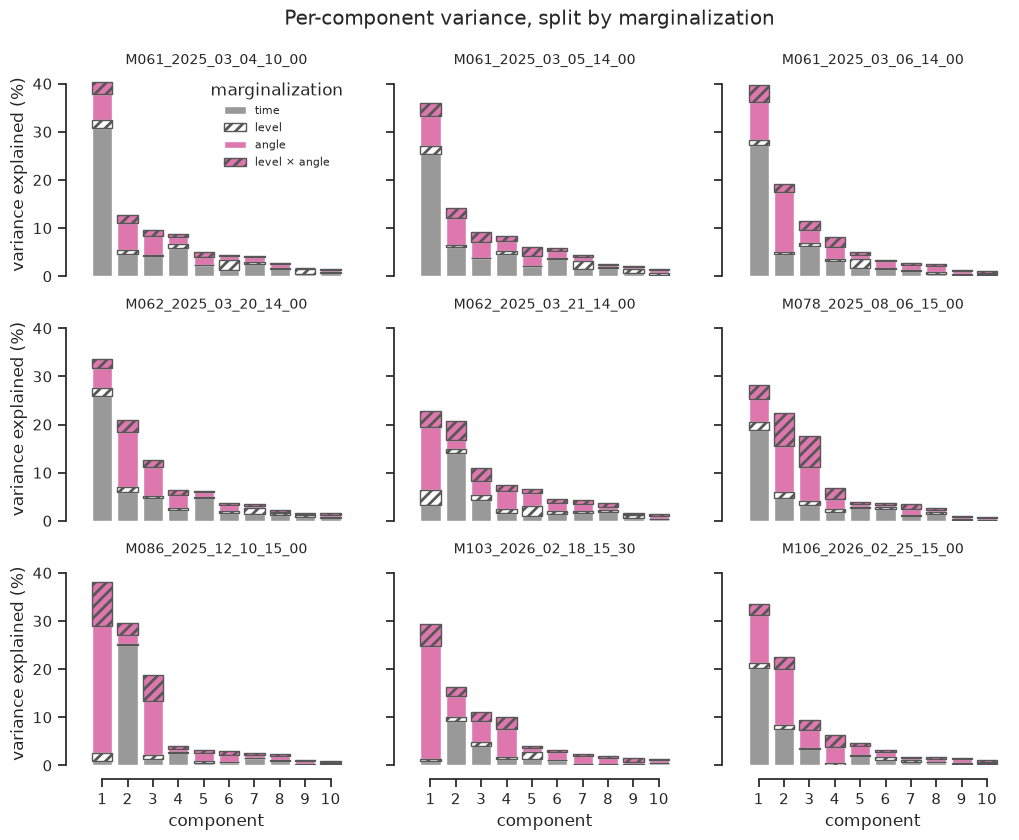

In [15]:
N_COMP = 10
x = np.arange(1, N_COMP + 1)

with vizutils.apply_plot_style("notebook"), plt.rc_context({"hatch.linewidth": 2}):
    fig, axs = plt.subplots(3, 3, figsize=(12, 9), sharex=True, sharey=True)
    for ax, (sess, r) in zip(axs.flat, dpca_res.items()):
        marg_var = dim.get_var_split(r["dpca"], r["X_psth"])[1]
        bottom = np.zeros(N_COMP)
        for j, key in enumerate(r["keys"]):
            hatched = "hatch" in bhv.FACTOR_BAR[bhv.MARG_STYLE[key]]  # drawn on top, so a neighbouring segment cannot cover the outline
            ax.bar(x, marg_var[j, :N_COMP], bottom=bottom, width=0.8, lw=1, label=MARG_NAME[key],
                   zorder=3 if hatched else 2, **bar_style(key))
            bottom += marg_var[j, :N_COMP]
        ax.set_title(sess, fontsize=10)
    axs[0, 0].legend(title="marginalization", frameon=False, fontsize=8, loc="upper right")
    axs[0, 0].set_xticks(x)
    for ax in axs[:, 0]:
        ax.set_ylabel("variance explained (%)")
    for ax in axs[-1]:
        ax.set_xlabel("component")
    fig.suptitle("Per-component variance, split by marginalization", y=0.95)
for ax in axs[:-1].ravel():  # after the `with`: the style's despine re-draws the bottom spine on exit
    ax.spines["bottom"].set_visible(False)
    ax.tick_params(bottom=False)
plt.show()

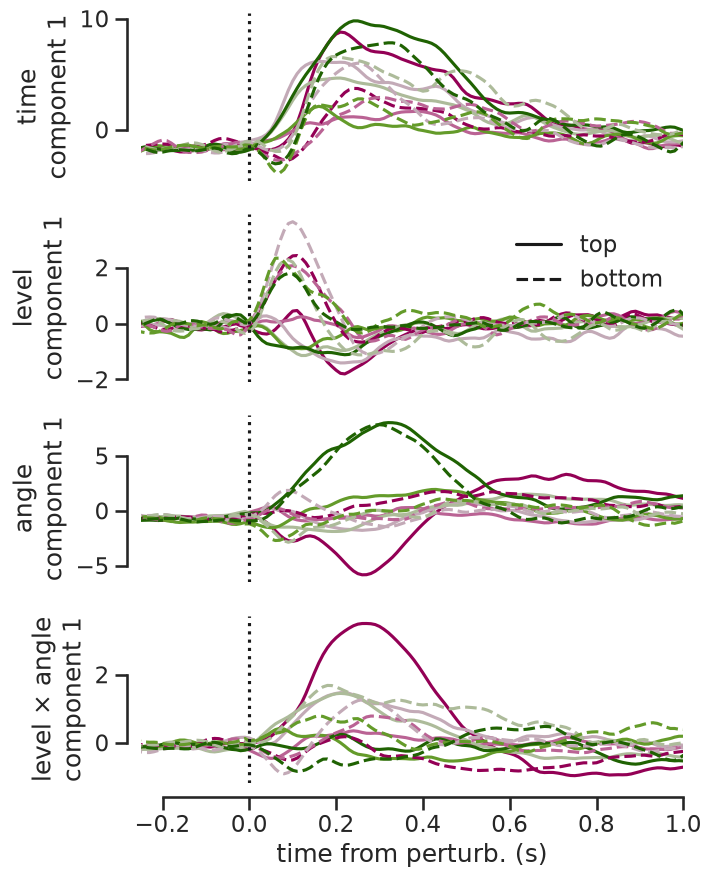

In [16]:
COMP = 0

r = dpca_res[EXAMPLE]
levels, angles = r["cond_values"]
Z = r["dpca"].transform(r["X_psth"])  # key -> (components, levels, angles, time)
t = np.arange(r["X_psth"].shape[-1]) / FS + RESPONSE[0]

with vizutils.apply_plot_style("talk"):
    fig, axs = plt.subplots(len(r["keys"]), 1, figsize=(7, 10), sharex=True)
    for ax, key in zip(axs, r["keys"]):
        for li, level in enumerate(levels):
            for ai, angle in enumerate(angles):
                ax.plot(t, Z[key][COMP, li, ai], color=bhv.ANGLE_COLOR[angle], ls=bhv.LEVEL_STYLE[level]["ls"])
        ax.axvline(0, color="k", ls=":")
        ax.set_ylabel(f"{MARG_NAME[key]}\ncomponent {COMP + 1}")
    axs[-1].set_xlabel("time from perturb. (s)")
    axs[0].set_xlim(-0.25, 1)
    legend = dict(loc="upper right", frameon=False)
    axs[list(r["keys"]).index("lt")].legend(
        handles=[Line2D([], [], color="k", ls=bhv.LEVEL_STYLE[lv]["ls"], label=Params.levelcode_to_str[lv]) for lv in levels],
        **legend,
    )
    # fig.suptitle(f"{EXAMPLE}: all conditions in each marginalization", y=0.95)
for ax in axs[:-1]:  # after the `with`: the style's despine re-draws the bottom spine on exit
    ax.spines["bottom"].set_visible(False)
    ax.tick_params(bottom=False)
plt.show()

## Shuffle results

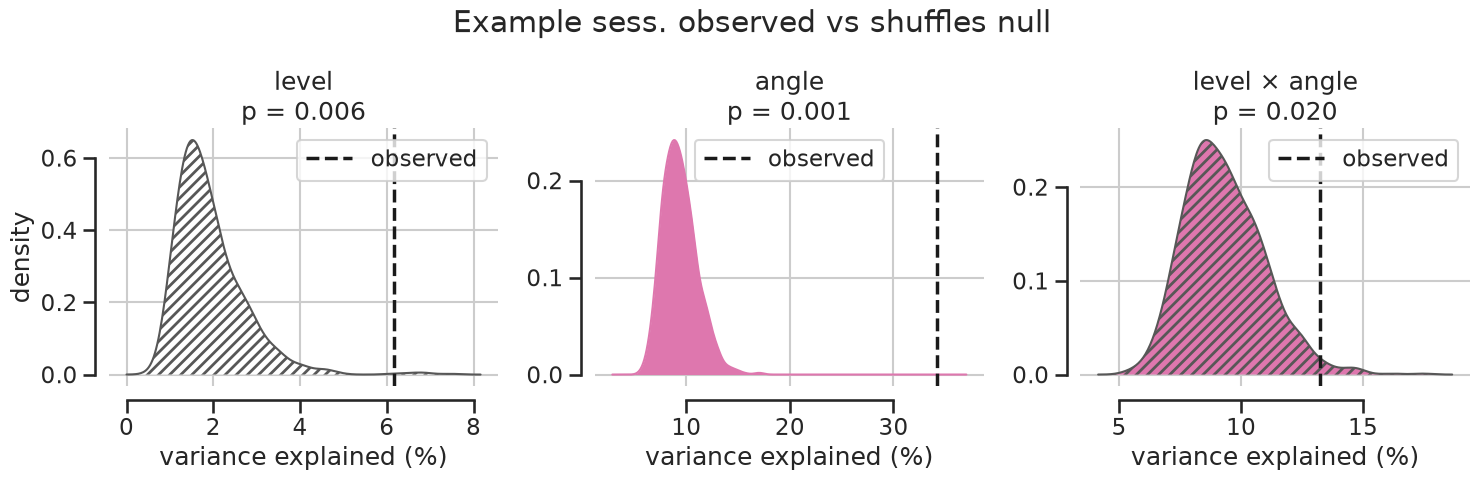

In [17]:
MARG = ["lt", "pt", "lpt"]  # time is left out: its share sits below the shuffle null by construction

r = dpca_res[EXAMPLE]
idx = [list(r["keys"]).index(k) for k in MARG]

with vizutils.apply_plot_style("talk"), plt.rc_context({"hatch.linewidth": 2}):
    fig, axs = plt.subplots(1, len(MARG), figsize=(15, 5))
    for ax, key, i in zip(axs, MARG, idx):
        null, obs = r["null"][:, i], r["observed"][i]
        lo, hi = min(null.min(), obs), max(null.max(), obs)
        grid = np.linspace(max(lo - 0.1 * (hi - lo), 0), hi + 0.1 * (hi - lo), 300)  # variance is not negative
        density = gaussian_kde(null)(grid)
        fill = bar_style(key)
        ax.fill_between(grid, density, lw=0, **fill)
        ax.plot(grid, density, color=fill.get("edgecolor", fill.get("color")), lw=1.5)
        ax.axvline(obs, lw=2.5, color='k', ls='--', label='observed')
        ax.set_title(f"{MARG_NAME[key]}\np = {r['p'][i]:.3f}")
        ax.set_xlabel("variance explained (%)")
        ax.grid()
        ax.legend()
    axs[0].set_ylabel("density")
    fig.suptitle(f" Example sess. observed vs shuffles null", y=0.95)
    plt.tight_layout()
plt.show()

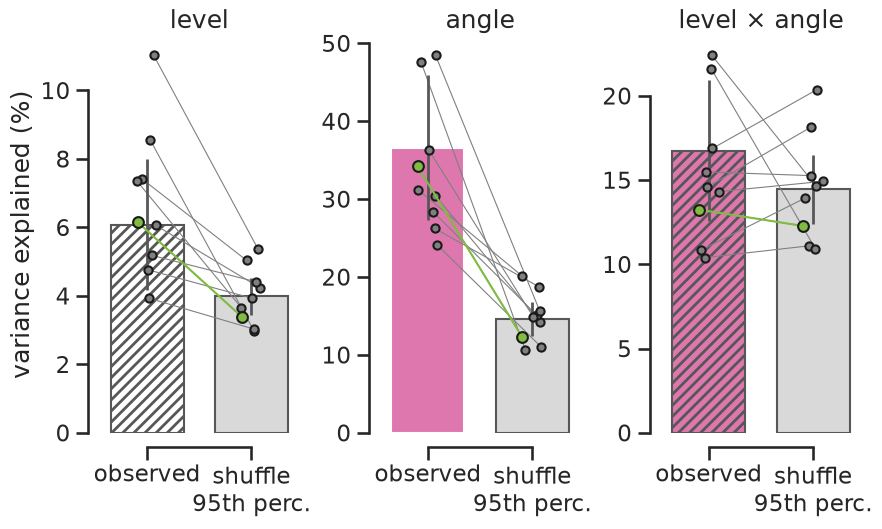

In [18]:
MAIN = ["lt", "pt", "lpt"]
sessions = list(dpca_res)
ex = sessions.index(EXAMPLE)
rng = np.random.default_rng(0)

with vizutils.apply_plot_style("talk"), plt.rc_context({"hatch.linewidth": 2}):
    fig, axs = plt.subplots(1, len(MAIN), figsize=(9, 5.5))  # one axis each, so every marginalization has its own scale
    for ax, key in zip(axs, MAIN):
        i = list(dpca_res[sessions[0]]["keys"]).index(key)
        observed = np.array([r["observed"][i] for r in dpca_res.values()])
        p95 = np.array([r["null_p95"][i] for r in dpca_res.values()])  # each session's own shuffle 95th percentile
        ax.bar(0, animal_means(observed, sessions).mean(), width=0.7, lw=1.5, **bar_style(key))
        ax.bar(1, animal_means(p95, sessions).mean(), width=0.7, lw=1.5, color="0.85", edgecolor=NEUTRAL)
        for x, v in ((0, observed), (1, p95)):  # mean +- std over animals, behind the session dots
            ax.errorbar(x, animal_means(v, sessions).mean(), yerr=animal_means(v, sessions).std(ddof=1), color=NEUTRAL, lw=2, capsize=0, zorder=2.5)
        jitter = rng.uniform(-0.1, 0.1, len(sessions))
        ax.plot([jitter, 1 + jitter], [observed, p95], color="0.5", lw=0.8, zorder=2)  # one line per session, observed to its own 95th percentile
        ax.scatter(jitter, observed, facecolor="0.5", edgecolor="k", s=35, zorder=3)
        ax.scatter(1 + jitter, p95, facecolor="0.5", edgecolor="k", s=35, zorder=3)
        ax.plot([jitter[ex], 1 + jitter[ex]], [observed[ex], p95[ex]], color=bhv.EXAMPLE_COLOR, lw=1.5, zorder=4)
        ax.scatter([jitter[ex], 1 + jitter[ex]], [observed[ex], p95[ex]], facecolor=bhv.EXAMPLE_COLOR, edgecolor="k", s=60, zorder=5,
                   label="example session")
        ax.set_xticks([0, 1], ["observed", "shuffle\n95th perc."])
        ax.set_title(MARG_NAME[key])
    axs[0].set_ylabel("variance explained (%)")
    # axs[0].legend(fontsize="small")
    plt.tight_layout()
plt.show()

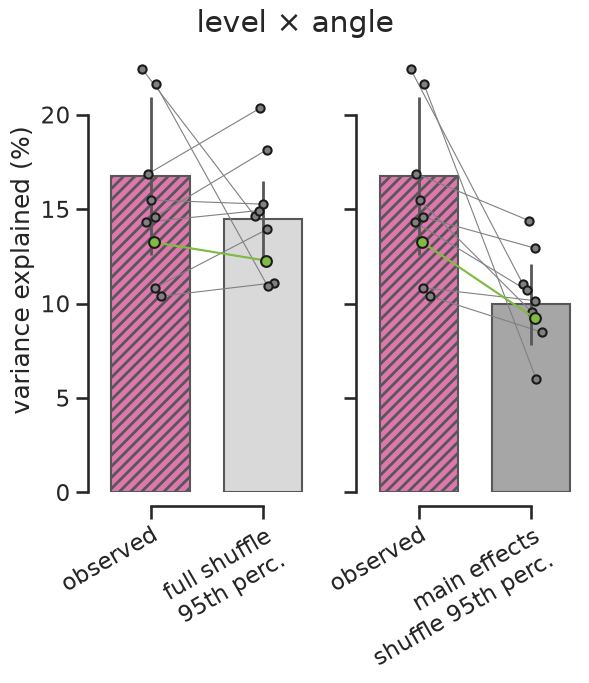

In [19]:
FL_DIR = Params.ACROSS_SESSION_RESULTS_DIR / "dpca-interaction-permutation" / "data"
fl = {sess: np.load(FL_DIR / f"{sess}.npz") for sess in sessions}
i = list(dpca_res[sessions[0]]["keys"]).index("lpt")

# the same observed lpt share against each session's own 95th percentile under the two nulls
cols = {
    "observed": np.array([dpca_res[s_]["observed"][i] for s_ in sessions]),
    "full shuffle\n95th perc.": np.array([dpca_res[s_]["null_p95"][i] for s_ in sessions]),
    "main effects\nshuffle 95th perc.": np.array([np.percentile(fl[s_]["null_pct"][:, i], 95) for s_ in sessions]),
}
bar_kw = [bar_style("lpt"), dict(color="0.85", edgecolor=NEUTRAL), dict(color="0.65", edgecolor=NEUTRAL)]
jitter = rng.uniform(-0.1, 0.1, len(sessions))
v = np.array(list(cols.values()))  # (columns, sessions)
xs = np.arange(2)[:, None] + jitter

with vizutils.apply_plot_style("talk"), plt.rc_context({"hatch.linewidth": 2}):
    fig, axs = plt.subplots(1, 2, figsize=(6, 7), sharey=True)  # observed against each null in turn
    for ax, k in zip(axs, (1, 2)):
        pair = v[[0, k]] 
        for x, col in ((0, 0), (1, k)):
            ax.bar(x, animal_means(v[col], sessions).mean(), width=0.7, lw=1.5, **bar_kw[col])
            ax.errorbar(x, animal_means(v[col], sessions).mean(), yerr=animal_means(v[col], sessions).std(ddof=1), color=NEUTRAL, lw=2, capsize=0, zorder=2.5)
        ax.plot(xs, pair, color="0.5", lw=0.8, zorder=2)  # one line per session, observed to its own 95th percentile
        ax.scatter(xs, pair, facecolor="0.5", edgecolor="k", s=35, zorder=3)
        ax.plot(xs[:, ex], pair[:, ex], color=bhv.EXAMPLE_COLOR, lw=1.5, zorder=4)
        ax.scatter(xs[:, ex], pair[:, ex], facecolor=bhv.EXAMPLE_COLOR, edgecolor="k", s=60, zorder=5)
        ax.set_xticks([0, 1], [list(cols)[0], list(cols)[k]])
    axs[0].set_ylabel("variance explained (%)")
    fig.suptitle(MARG_NAME["lpt"], y=0.97)
for ax in axs:  
    ax.tick_params(axis="x", labelrotation=30)
    plt.setp(ax.get_xticklabels(), ha="right", rotation_mode="anchor")
plt.tight_layout()
plt.show()

## Limbs projections

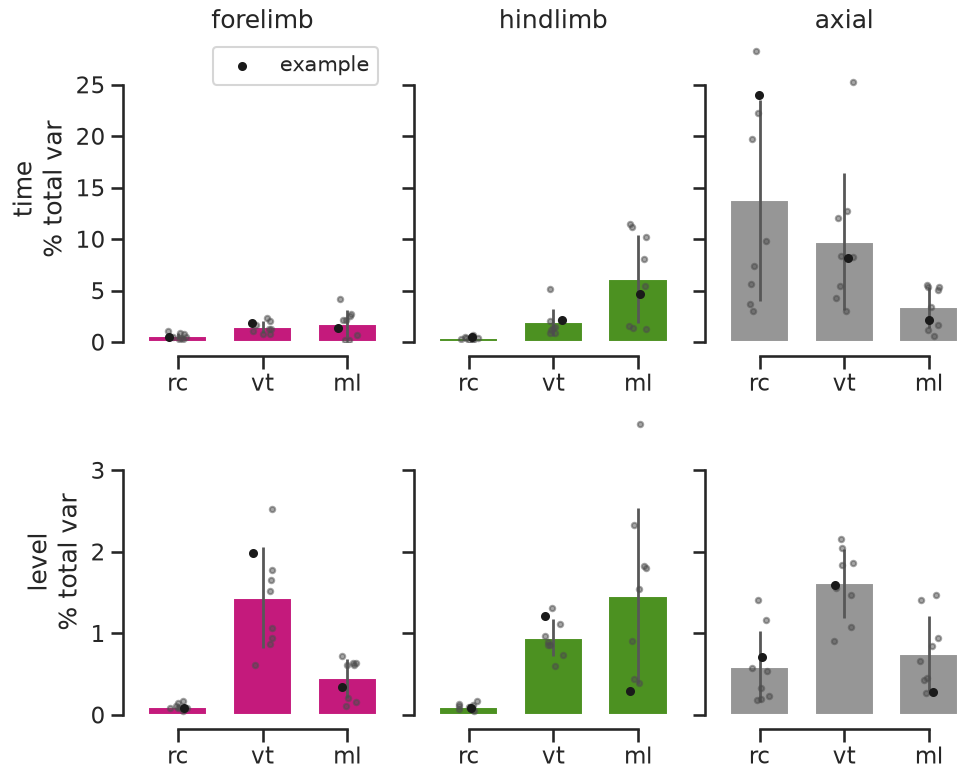

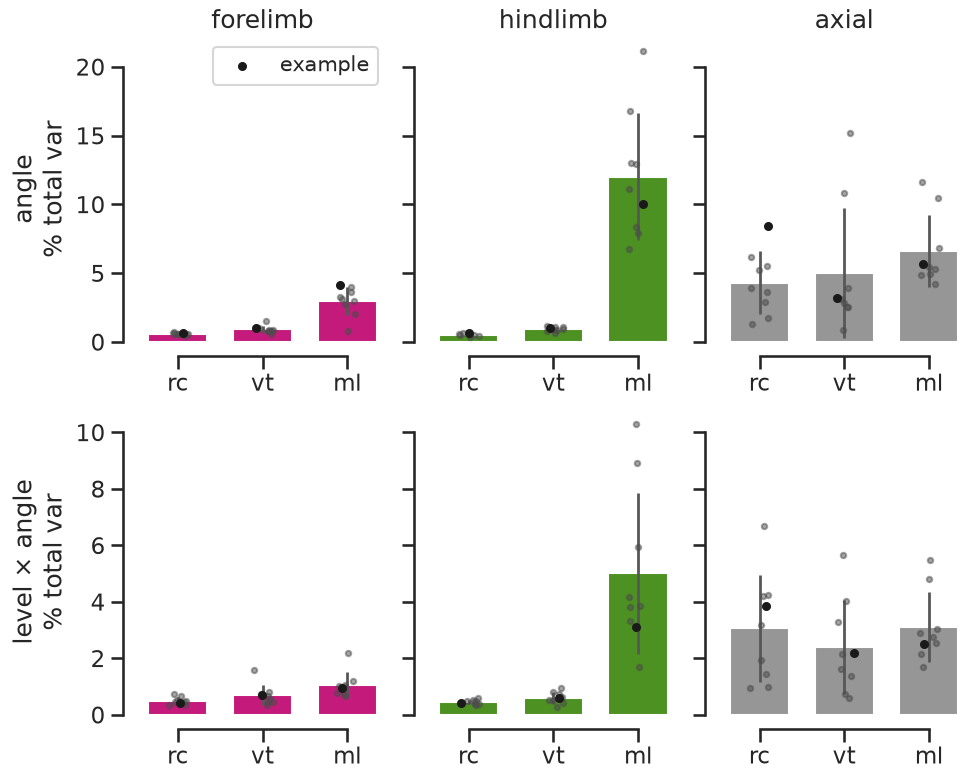

In [21]:
ROWS = ["t", "lt", "pt", "lpt"]
dim_of, region_mask = bhv.channel_regions(s[EXAMPLE]["bhv_keypoints"])
regions = REGIONS

sessions = list(dpca_res)
ex = sessions.index(EXAMPLE)
rng = np.random.default_rng(0)
tables = np.stack([bhv.region_dim_table(r["dpca"], r["X_psth"], dim_of, region_mask, ROWS) for r in dpca_res.values()])  # (sessions, ROWS, regions, DIMS)

for group in (["t", "lt"], ["pt", "lpt"]):  # two figures: time and level, then angle and level x angle
    with vizutils.apply_plot_style("talk"):
        fig, axs = plt.subplots(len(group), len(regions), figsize=(10, 8), sharey="row")
        for k, marg in enumerate(group):
            ri = ROWS.index(marg)
            for ci, region in enumerate(regions):
                ax = axs[k, ci]
                for di in range(len(DIMS)):
                    v = tables[:, ri, ci, di]
                    ax.bar(di, v.mean(), width=0.7, color=bhv.GROUP_COLOR[region])
                    ax.errorbar(di, v.mean(), yerr=v.std(ddof=1), color=NEUTRAL, lw=2, capsize=0, zorder=2.5)
                    x = di + rng.uniform(-0.12, 0.12, len(v))
                    ax.scatter(np.delete(x, ex), np.delete(v, ex), facecolor="0.3", s=15, zorder=3, alpha=0.5)
                    ax.scatter(x[ex], v[ex], facecolor='k', edgecolor="k", s=25, zorder=5,
                               label="example" if k == ci == di == 0 else None)
                ax.set_xticks(range(len(DIMS)), DIMS)
                if k == 0:
                    ax.set_title(region)
                if ci == 0:
                    ax.set_ylabel(f"{MARG_NAME[marg]}\n% total var")
        # fig.suptitle(f"mean ± std over {len(sessions)} sessions; dots = sessions", y=0.97)
        axs[0, 0].legend(fontsize="small")
        plt.tight_layout()
    plt.show()

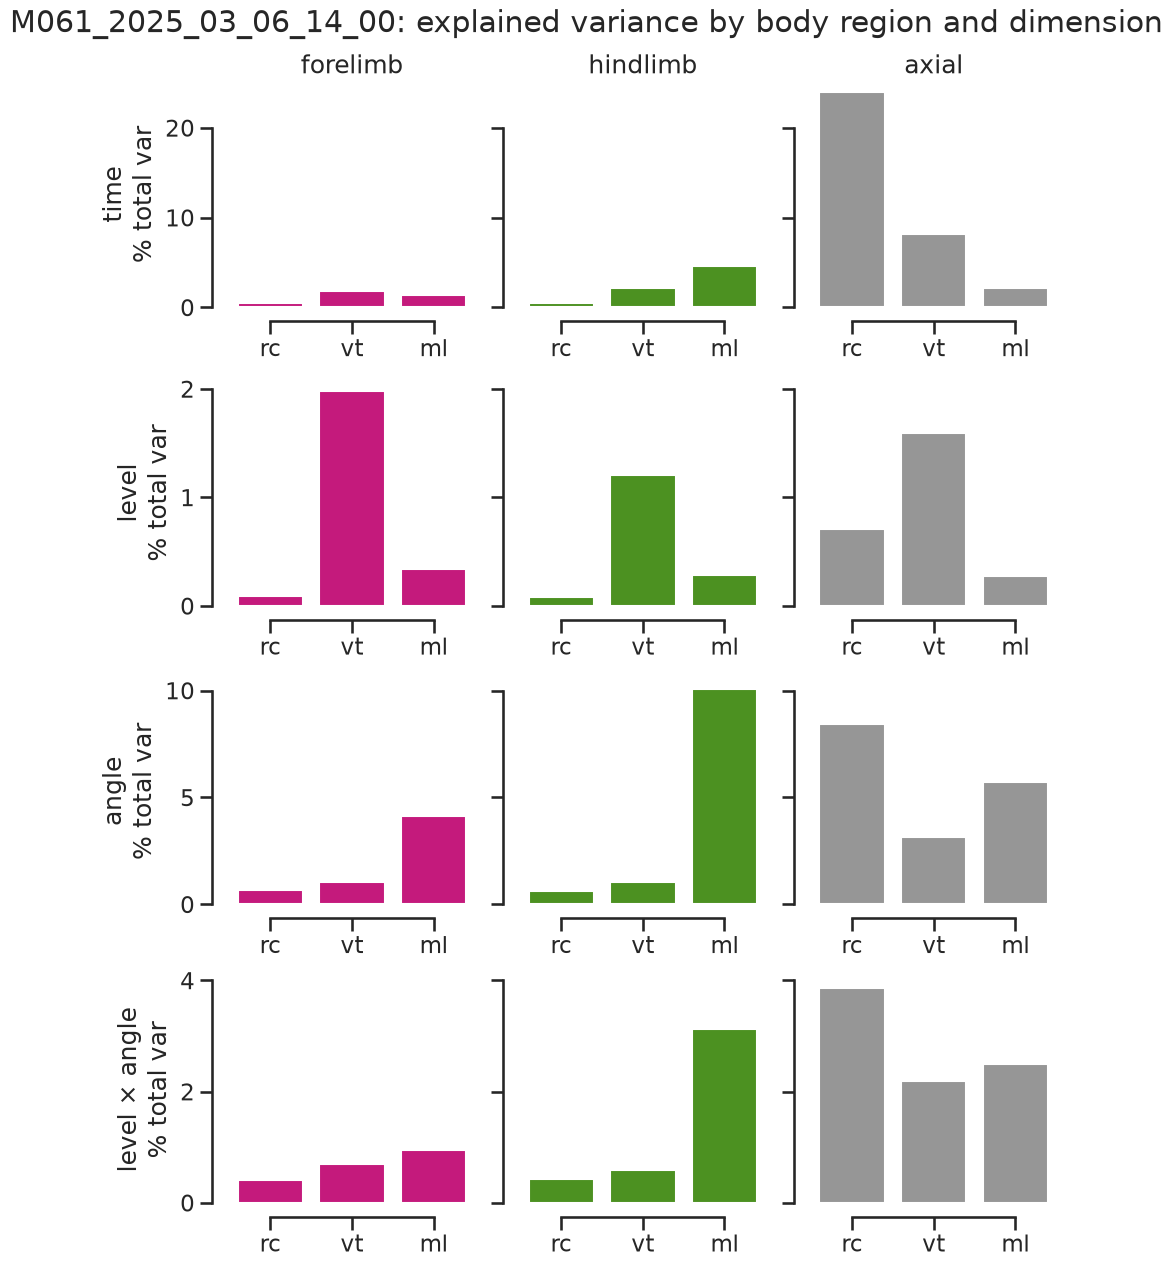

In [ ]:
table = tables[sessions.index(EXAMPLE)]  # the example session's slice of the table above

with vizutils.apply_plot_style("talk"):
    fig, axs = plt.subplots(len(ROWS), len(regions), figsize=(10, 13), sharey="row")
    for ri, marg in enumerate(ROWS):
        for ci, region in enumerate(regions):
            ax = axs[ri, ci]
            ax.bar(DIMS, table[ri, ci], color=bhv.GROUP_COLOR[region])
            if ri == 0:
                ax.set_title(region)
            if ci == 0:
                ax.set_ylabel(f"{MARG_NAME[marg]}\n% total var")
    fig.suptitle(f"{EXAMPLE}: explained variance by body region and dimension", y=0.97)
    plt.tight_layout()
plt.show()

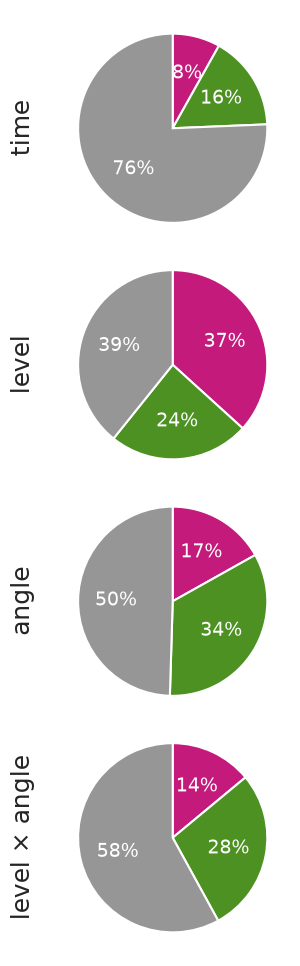

In [ ]:
with vizutils.apply_plot_style("talk"):
    fig, axs = plt.subplots(len(ROWS), 1, figsize=(3, 10))  # dimensions pooled: one pie of the regions per marginalization
    for ax, ri, marg in zip(axs, range(len(ROWS)), ROWS):
        wedges, *_ = ax.pie(
            table[ri].sum(axis=-1), colors=[bhv.GROUP_COLOR[g] for g in regions], startangle=90, counterclock=False,
            autopct=lambda pct: f"{pct:.0f}%" if pct >= 5 else "", textprops=dict(color="w", fontsize=14),
        )
        ax.set_ylabel(MARG_NAME[marg])
    # fig.legend(wedges, list(regions), loc="lower center", ncol=len(regions), frameon=False, fontsize="small")
    # fig.suptitle("dimensions pooled", y=0.97)
    plt.tight_layout(h_pad=0)
    fig.subplots_adjust(hspace=0)  # closes the vertical gap between the pies
plt.show()

<Figure size 640x480 with 0 Axes>

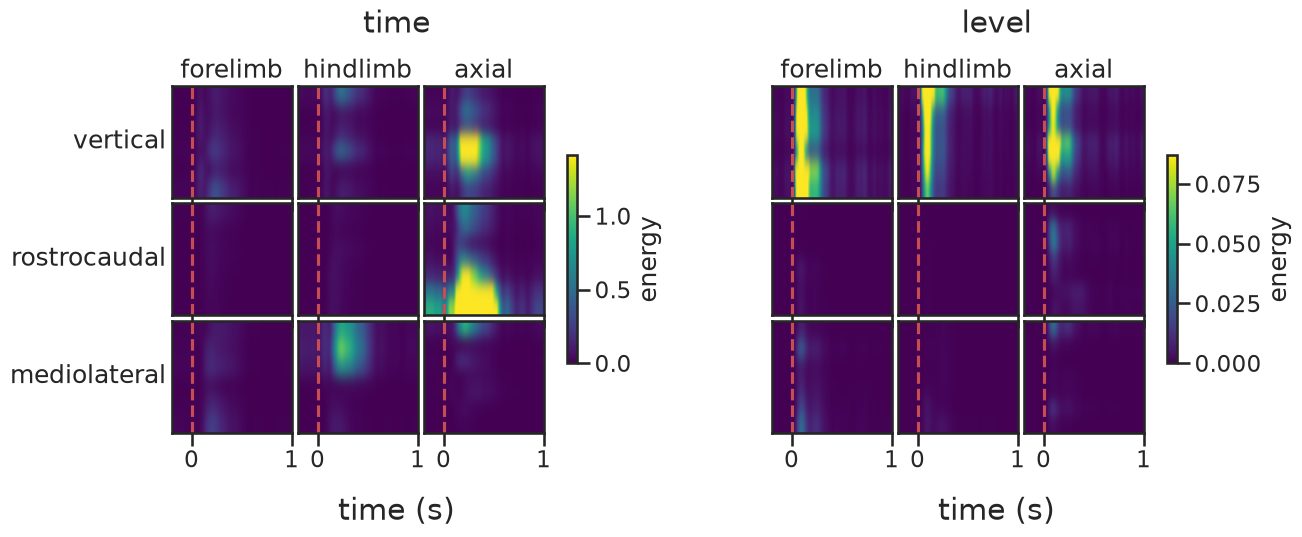

<Figure size 640x480 with 0 Axes>

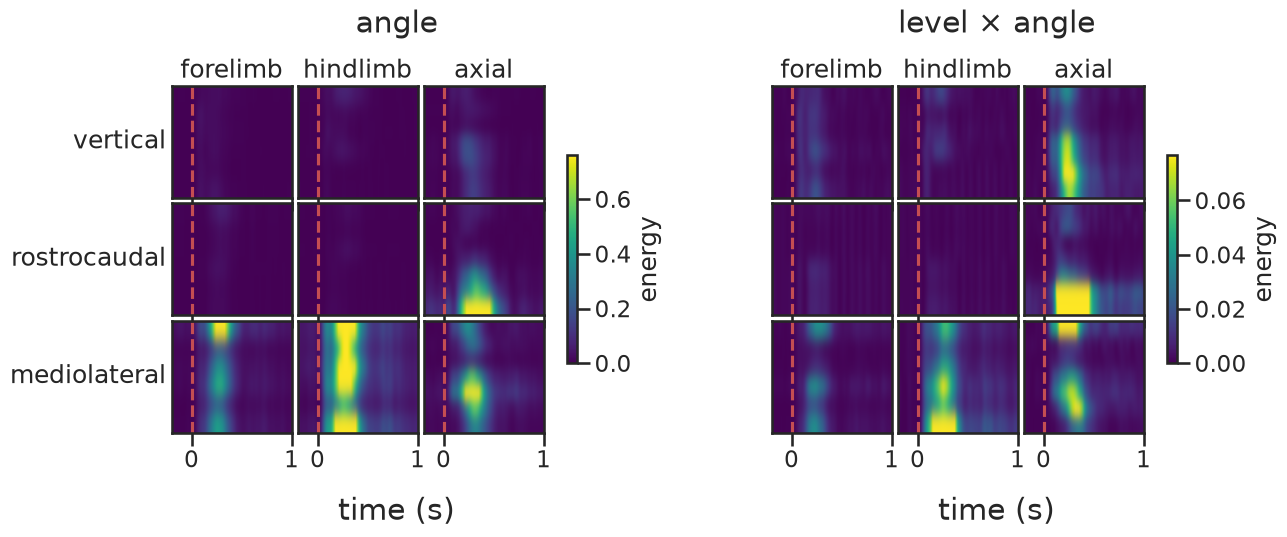

In [128]:
dim_names = ["vt", "rc", "ml"]
dim_label = {"vt": "vertical", "rc": "rostrocaudal", "ml": "mediolateral"}

r = dpca_res[EXAMPLE]
t = np.arange(r["X_psth"].shape[-1]) / FS + RESPONSE[0]
Z = r["dpca"].transform(r["X_psth"])  # marginalization -> (components, levels, angles, time)


energy = lambda marg: bhv.channel_energy(r["dpca"], Z, marg)


for group in (["t", "lt"], ["pt", "lpt"]):  # two figures: time and level, then angle and level x angle
    with vizutils.apply_plot_style("talk"):
        fig = plt.figure(figsize=(12, 4.5))
        subfigs = fig.subfigures(1, len(group), wspace=0.0)
        for i, (subfig, marg) in enumerate(zip(subfigs, group)):
            e = energy(marg)
            axs = subfig.subplots(len(dim_names), len(regions), sharex="all", gridspec_kw=dict(hspace=0.05, wspace=0.05))
            # subfig.subplots_adjust(left=0.3, right=0.95, top=0.8, bottom=0.15)  # same margins in both, so the axes are the same size
            for col, region in enumerate(regions):
                for row, d in enumerate(dim_names):
                    arr = e[region_mask[region] & (dim_of == d)]  # one row per keypoint in the region
                    ax = axs[row, col]
                    im = ax.imshow(arr, extent=[t[0], t[-1], arr.shape[0], 0], aspect="auto", interpolation="gaussian",
                                   cmap="viridis", vmin=0, vmax=np.percentile(e, 99))
                    ax.axvline(0, color="r", ls="--")
                    ax.set_yticks([])
                    if row == 0:
                        ax.set_title(region)
                    if col == 0 and i == 0:
                        ax.set_ylabel(dim_label[d], rotation=0, ha="right", va="center")
            axs[0, 0].set_xlim(-0.2, 1)
            subfig.colorbar(im, ax=axs, label="energy", shrink=0.6)
            subfig.suptitle(MARG_NAME[marg], y=1.05)
            subfig.supxlabel("time (s)", y=-0.1)
        plt.show()

<Figure size 640x480 with 0 Axes>

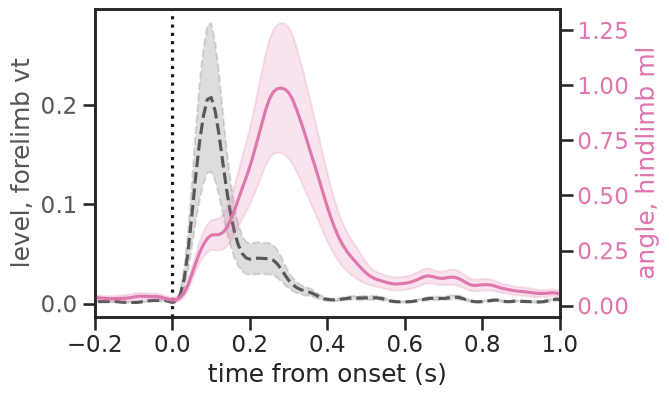

In [126]:
(level_group, level_dim), (angle_group, angle_dim) = ("forelimb", "vt"), ("hindlimb", "ml")
level_e = energy("lt")[region_mask[level_group] & (dim_of == level_dim)]  # (channels, time)
angle_e = energy("pt")[region_mask[angle_group] & (dim_of == angle_dim)]
pink = bhv.FACTOR_COLOR["angle"]

with vizutils.apply_plot_style('talk'):
    fig, ax = plt.subplots(figsize=(6, 4))
    ax2 = ax.twinx()
    vizutils.shaded_errorbar(ax, t, level_e.T, color=NEUTRAL, ls="--")  # mean +- std over the channels
    vizutils.shaded_errorbar(ax2, t, angle_e.T, color=pink)
    ax.set_ylabel(f"level, {level_group} {level_dim}", color=NEUTRAL)
    ax2.set_ylabel(f"angle, {angle_group} {angle_dim}", color=pink)
    ax.tick_params(axis="y", labelcolor=NEUTRAL)
    ax2.tick_params(axis="y", labelcolor=pink)
    ax.set_xlabel("time from onset (s)")
    ax.set_xlim(-0.2, 1)
    ax.axvline(0, color="k", ls=":")
    # ax.set_title("Energy in keypoint x marginalization")
    plt.show()

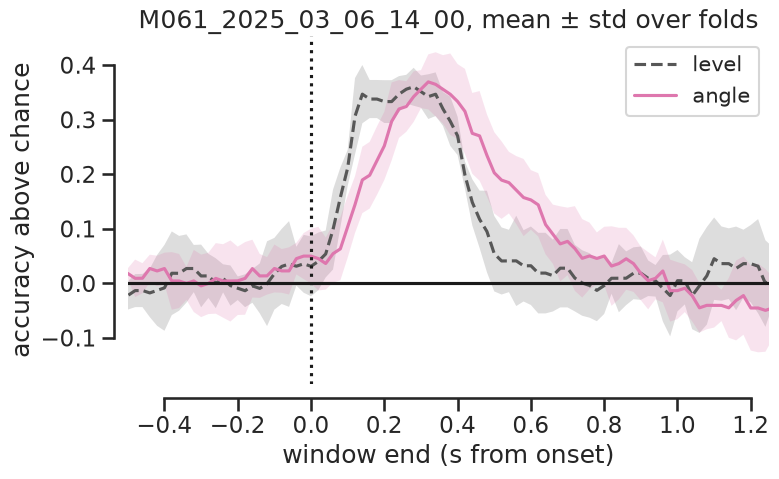

In [147]:
DEC_CACHE = CACHE / "decoding"
TAG = "bhv_rot_w30_s2_shuf0_dims"
line_style = {
    "angle": bhv.FACTOR_LINE["angle"],
    "level": {**bhv.FACTOR_LINE["level"], "color": NEUTRAL},
    "sol_id": bhv.FACTOR_LINE["level×angle"],
}

dec = np.load(DEC_CACHE / f"{EXAMPLE}_{TAG}.npz")
t_end = dec["time_end"]

with vizutils.apply_plot_style("talk"):
    fig, ax = plt.subplots(figsize=(8, 5))
    for name in ("level", "angle"):
        above = dec[f"{name}_mw"] - dec[f"{name}_chance_majority"]  # (windows, folds), accuracy above chance
        m, std = above.mean(axis=1), above.std(axis=1, ddof=1)
        ax.fill_between(t_end, m - std, m + std, color=line_style[name]["color"], alpha=0.2, lw=0)
        ax.plot(t_end, m, label=name, **line_style[name])
    ax.axhline(0, color="k")  # chance
    ax.axvline(0, color="k", ls=":")
    ax.set_xlim(-0.5, 1.25)
    ax.set_xlabel("window end (s from onset)")
    ax.set_ylabel("accuracy above chance")
    ax.set_title(f"{EXAMPLE}, mean ± std over folds")
    ax.legend(fontsize="small")
    plt.tight_layout()
plt.show()

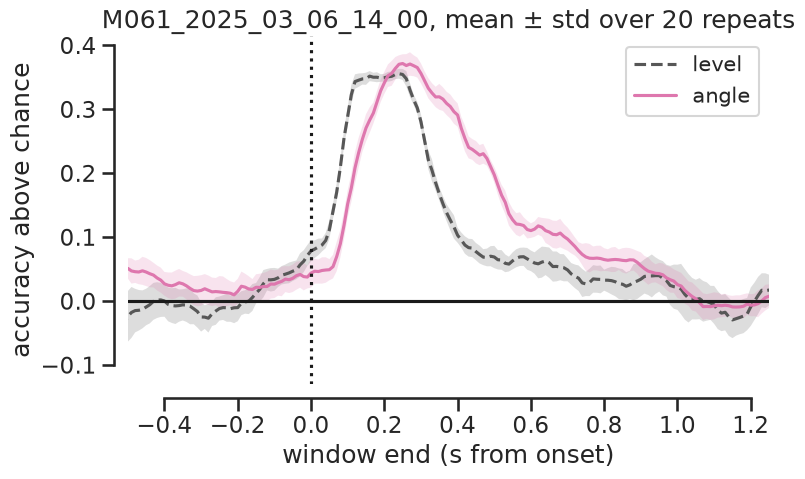

In [146]:
line_style = {"level": {**bhv.FACTOR_LINE["level"], "color": NEUTRAL}, "angle": bhv.FACTOR_LINE["angle"]}

rep = np.load(CACHE / "decoding" / f"{EXAMPLE}_ep_X_w20_s1_rep20.npz")
t_axis = rep["t_axis"]

with vizutils.apply_plot_style("talk"):
    fig, ax = plt.subplots(figsize=(8, 5))
    for name in line_style:
        above = rep[f"rep_{name}"]  # (repeats, windows); already accuracy above chance, not raw accuracy
        m, std = above.mean(axis=0), above.std(axis=0, ddof=1)
        ax.fill_between(t_axis, m - std, m + std, color=line_style[name]["color"], alpha=0.2, lw=0)
        ax.plot(t_axis, m, label=name, **line_style[name])
    ax.axhline(0, color="k")  # chance
    ax.axvline(0, color="k", ls=":")
    ax.set_xlabel("window end (s from onset)")
    ax.set_ylabel("accuracy above chance")
    ax.set_title(f"{EXAMPLE}, mean ± std over {len(rep['rep_level'])} repeats")
    ax.legend(fontsize="small")
    ax.set_xlim(-0.5, 1.25)
    plt.tight_layout()
plt.show()

In [148]:
METRICS = ["t_rise50", "t_peak", "t_fall50", "fwhm"]


rows = []
for sess in SESSIONS_DPCA:
    rep = np.load(CACHE / "decoding" / f"{sess}_ep_X_w20_s1_rep20.npz")
    for target in ("level", "angle"):
        rows.append(dict(session=sess, target=target, **bhv.timing_metrics_grid(rep["t_axis"], rep[f"curve_{target}_avg"])))
timing = pd.DataFrame(rows).pivot(index="session", columns="target")  # columns: (metric, target)

ref = pd.read_csv(CACHE / "decoding" / "ep_X_w20_s1_rep20_summary_metrics.csv").set_index("session")
print("matches the cached summary:", all(np.allclose(timing[(m, t_)], ref.loc[timing.index, f"{m}_{t_}"]) for m in METRICS for t_ in ("level", "angle")))
timing.round(3)

matches the cached summary: True


t_rise50       t_peak       t_fall50        fwhm      
target                   angle level  angle level    angle level angle level
session                                                                     
M061_2025_03_04_10_00     0.12  0.07   0.23  0.14     0.47  0.37  0.35  0.30
M061_2025_03_05_14_00     0.12  0.07   0.22  0.16     0.46  0.34  0.34  0.27
M061_2025_03_06_14_00     0.12  0.08   0.25  0.24     0.50  0.34  0.38  0.26
M062_2025_03_20_14_00     0.15  0.08   0.24  0.17     0.48  0.36  0.33  0.28
M062_2025_03_21_14_00     0.14  0.07   0.25  0.20     0.47  0.37  0.33  0.30
M078_2025_08_06_15_00     0.14  0.07   0.24  0.14     0.39  0.31  0.25  0.24
M086_2025_12_10_15_00     0.11  0.07   0.24  0.15     0.69  0.34  0.58  0.27
M103_2026_02_18_15_30     0.12  0.06   0.20  0.14     0.44  0.33  0.32  0.27
M106_2026_02_25_15_00     0.14  0.07   0.25  0.15     0.50  0.31  0.36  0.24

In [149]:
rows = []
for m in METRICS:
    level, angle = timing[(m, "level")].to_numpy(), timing[(m, "angle")].to_numpy()
    delta = angle - level
    f = lambda v: f"{np.median(v):.2f} [{v.min():.2f}, {v.max():.2f}]"
    rows.append({"metric (s)": m, "level": f(level), "angle": f(angle), "angle - level": f(delta),
                 "sessions positive": f"{(delta > 0).sum()}/{len(delta)}", "Wilcoxon p": f"{stats.wilcoxon(delta).pvalue:.3f}"})
pd.DataFrame(rows).set_index("metric (s)")

,level,angle,angle - level,sessions positive,Wilcoxon p
metric (s),,,,,
t_rise50,"0.07 [0.06, 0.08]","0.12 [0.11, 0.15]","0.06 [0.04, 0.07]",9/9,0.004
t_peak,"0.15 [0.14, 0.24]","0.24 [0.20, 0.25]","0.07 [0.01, 0.10]",9/9,0.004
t_fall50,"0.34 [0.31, 0.37]","0.47 [0.39, 0.69]","0.12 [0.08, 0.35]",9/9,0.004
fwhm,"0.27 [0.24, 0.30]","0.34 [0.25, 0.58]","0.05 [0.01, 0.31]",9/9,0.004


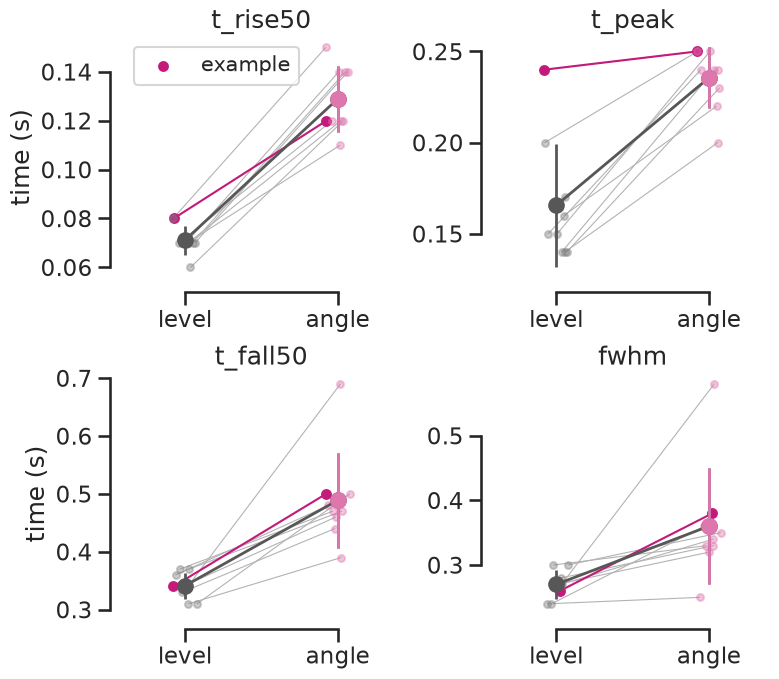

In [189]:
rng = np.random.default_rng(0)
pink = bhv.FACTOR_COLOR["angle"]
ex = timing.index.get_loc(EXAMPLE)

with vizutils.apply_plot_style("talk"):
    fig, axs = plt.subplots(2, 2, figsize=(8, 7))
    for k, (ax, m) in enumerate(zip(axs.flat, METRICS)):
        v = np.stack([timing[(m, "level")].to_numpy(), timing[(m, "angle")].to_numpy()])  # (level/angle, sessions)
        x = np.arange(2)[:, None] + rng.uniform(-0.08, 0.08, v.shape[1])
        ax.plot(x, v, color="0.7", lw=0.8, zorder=1)  # one line per session, level to angle
        ax.scatter(np.delete(x[0], ex), np.delete(v[0], ex), facecolor="0.5", s=25, zorder=3, alpha=0.4)
        ax.scatter(np.delete(x[1], ex), np.delete(v[1], ex), facecolor=pink, s=25, zorder=3, alpha=0.4)
        ax.plot(x[:, ex], v[:, ex], color=ACCENT, lw=1.5)  # the example session
        ax.scatter(x[:, ex], v[:, ex], facecolor=ACCENT, s=40, label="example" if k == 0 else None)
        ax.errorbar(np.arange(2), v.mean(axis=1), yerr=v.std(axis=1, ddof=1), fmt="-o", color=NEUTRAL, ms=11, lw=2, capsize=0, zorder=4)
        ax.errorbar(1, v[1].mean(), yerr=v[1].std(ddof=1), fmt="o", color=pink, lw=2, capsize=0, zorder=5, ms=11)  # angle in its own colour
        ax.set_xticks([0, 1], ["level", "angle"])
        ax.set_xlim(-0.4, 1.4)
        ax.set_title(m)
    for ax in axs[:, 0]:
        ax.set_ylabel("time (s)")
    axs[0, 0].legend(fontsize="small")
    plt.tight_layout()
plt.show()

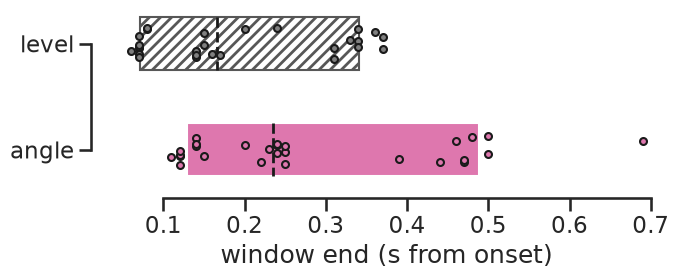

In [167]:
box_style = {"level": {**bhv.FACTOR_BAR["level"], "edgecolor": NEUTRAL}, "angle": bhv.FACTOR_BAR["angle"]}
dot_color = {"level": "0.5", "angle": bhv.FACTOR_COLOR["angle"]}
rng = np.random.default_rng(0)

with vizutils.apply_plot_style("talk"), plt.rc_context({"hatch.linewidth": 2}):
    fig, ax = plt.subplots(figsize=(7, 3))
    for y, target in enumerate(("level", "angle")):
        rise, peak, fall = (timing[(m, target)].to_numpy() for m in ("t_rise50", "t_peak", "t_fall50"))
        ax.barh(y, fall.mean() - rise.mean(), left=rise.mean(), height=0.5, lw=1.5, **box_style[target])  # mean rise to mean fall
        ax.vlines(peak.mean(), y - 0.25, y + 0.25, color="k", ls="--", lw=2, zorder=4)  # mean peak
        for v in (rise, peak, fall):  # one dot per session for each landmark
            ax.scatter(v, y + rng.uniform(-0.15, 0.15, len(v)), facecolor=dot_color[target], edgecolor="k", s=25, zorder=5)
    ax.set_yticks([0, 1], ["level", "angle"])
    ax.invert_yaxis()
    ax.set_xlabel("window end (s from onset)")
    plt.tight_layout()
plt.show()

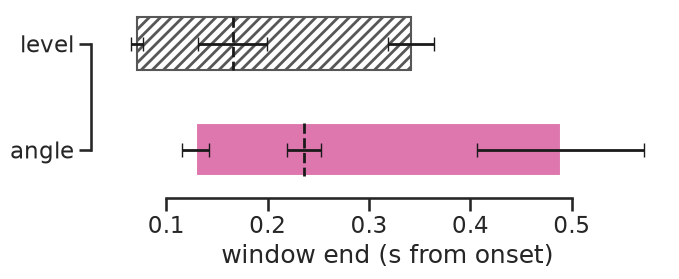

In [173]:
box_style = {"level": {**bhv.FACTOR_BAR["level"], "edgecolor": NEUTRAL}, "angle": bhv.FACTOR_BAR["angle"]}

with vizutils.apply_plot_style("talk"), plt.rc_context({"hatch.linewidth": 2}):
    fig, ax = plt.subplots(figsize=(7, 3))
    for y, target in enumerate(("level", "angle")):
        rise, peak, fall = (timing[(m, target)].to_numpy() for m in ("t_rise50", "t_peak", "t_fall50"))
        ax.barh(y, fall.mean() - rise.mean(), left=rise.mean(), height=0.5, lw=1.5, **box_style[target])  # mean rise to mean fall
        ax.vlines(peak.mean(), y - 0.25, y + 0.25, color="k", ls="--", lw=2, zorder=4)  # mean peak
        for v in (rise, peak, fall):  # mean +- std over sessions for each landmark
            ax.errorbar(v.mean(), y, xerr=v.std(ddof=1), fmt="o", color="k", lw=2, ms=0, capsize=5, capthick=2, zorder=5)
    ax.set_yticks([0, 1], ["level", "angle"])
    ax.invert_yaxis()
    ax.set_xlabel("window end (s from onset)")
    plt.tight_layout()
plt.show()